# Projeto Avaliativo — Análise de Dados com Python [T6]

**Fase 3: camada Gold e visualização de dados públicos de viagens a serviço (2025, seis meses).**

Tecnologias: Python, PostgreSQL, Pandas, Matplotlib, Jupyter Notebook e GitHub.

**Atenção:** os valores são calculados a partir das tabelas reais no PostgreSQL. 

## 1. Preparação e conexão com o PostgreSQL

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from banco import conectar

# Ajustes visuais para graficos claros e legiveis.
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

PASTA_GRAFICOS = Path('graficos')
PASTA_GRAFICOS.mkdir(exist_ok=True)

conexao = conectar()
print('Conectado ao PostgreSQL!')

def consultar(sql):
    """Executa SELECT e transforma o resultado em tabela Pandas."""
    with conexao.cursor() as cursor:
        cursor.execute(sql)
        nomes = [coluna.name for coluna in cursor.description]
        return pd.DataFrame(cursor.fetchall(), columns=nomes)

def mostrar_tabela(tabela):
    """Mostra os valores da pergunta de negocio em formato de tabela."""
    display(tabela)

def grafico_barras(tabela, coluna_nome, coluna_valor, titulo, eixo_x, arquivo):
    """Mostra um grafico horizontal e salva a imagem PNG em graficos/."""
    if tabela.empty:
        print('Sem dados para gerar o grafico:', titulo)
        return
    fig, ax = plt.subplots(figsize=(10, max(4, len(tabela) * 0.65)))
    dados = tabela.iloc[::-1]
    ax.barh(dados[coluna_nome].astype(str),
            dados[coluna_valor].astype(float), label=eixo_x)
    ax.set_title(titulo)
    ax.set_xlabel(eixo_x)
    ax.set_ylabel(coluna_nome.replace('_', ' ').title())
    ax.legend(loc='best')
    fig.tight_layout()
    fig.savefig(PASTA_GRAFICOS / arquivo, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Conectado ao PostgreSQL!


## 2. Conferência das tabelas Raw e Silver

In [13]:
contagens = consultar("""
SELECT 'raw_viagem' AS tabela, COUNT(*) AS registros FROM raw_viagem
UNION ALL SELECT 'raw_pagamento', COUNT(*) FROM raw_pagamento
UNION ALL SELECT 'raw_passagem', COUNT(*) FROM raw_passagem
UNION ALL SELECT 'raw_trecho', COUNT(*) FROM raw_trecho
UNION ALL SELECT 'silver_viagem', COUNT(*) FROM silver_viagem
UNION ALL SELECT 'silver_pagamento', COUNT(*) FROM silver_pagamento
UNION ALL SELECT 'silver_passagem', COUNT(*) FROM silver_passagem
UNION ALL SELECT 'silver_trecho', COUNT(*) FROM silver_trecho
""")
mostrar_tabela(contagens)

,tabela,registros
0,silver_passagem,167260
1,raw_passagem,167260
2,silver_viagem,341860
3,silver_pagamento,606916
4,raw_pagamento,606916
5,raw_viagem,341860
6,raw_trecho,763349
7,silver_trecho,763349


## 3. Três perguntas consultadas diretamente na Silver (SQL + tabela + gráfico)

### Pergunta 1 — Quais são os cinco órgãos superiores com maior custo total?

Soma **uma vez por viagem** o valor calculado na Silver. Gastos são `diárias + passagens + outros − devoluções`.

,orgao,quantidade_viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,486933121.65
1,Ministério da Defesa,61912,156070304.49
2,Ministério da Educação,65295,111291349.34
3,Ministério do Meio Ambiente e Mudança do Clima,19413,49697710.16
4,Ministério da Previdência Social,8190,40417309.06


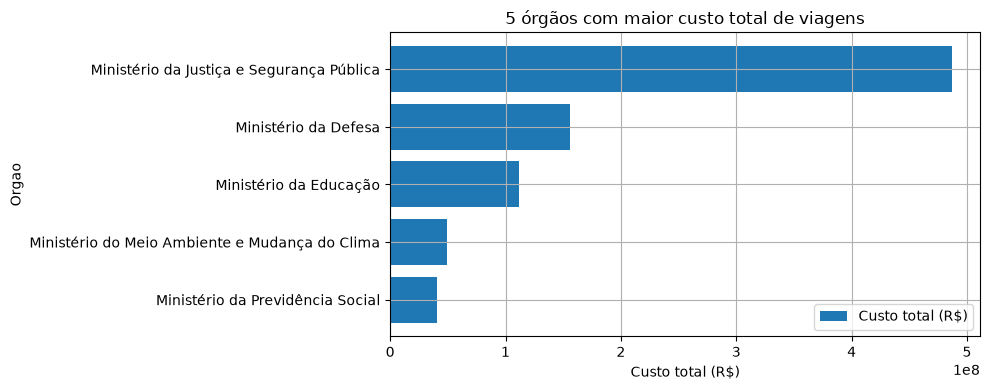

In [3]:
sql_1 = """
SELECT nome_orgao_superior AS orgao,
       COUNT(*) AS quantidade_viagens,
       ROUND(SUM(valor_total), 2) AS custo_total
FROM silver_viagem
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5;
"""
df1 = consultar(sql_1)
mostrar_tabela(df1)
grafico_barras(df1, 'orgao', 'custo_total',
              '5 órgãos com maior custo total de viagens',
              'Custo total (R$)', '01_orgaos_maiores_custos.png')

### Pergunta 2 — Quais os três destinos com maior custo médio por viagem?
Um mesmo deslocamento pode ter vários trechos. Foi usado `DISTINCT` para contar **cada viagem uma única vez em cada destino**. A localidade é a combinação cidade/UF. O custo considerado é o custo total da viagem, não de um trecho isolado.

,destino,quantidade_viagens,custo_medio
0,Tejupá / São Paulo,1,115175.00
1,Chavantes / São Paulo,1,114557.01
2,Teolândia / Bahia,1,109322.50


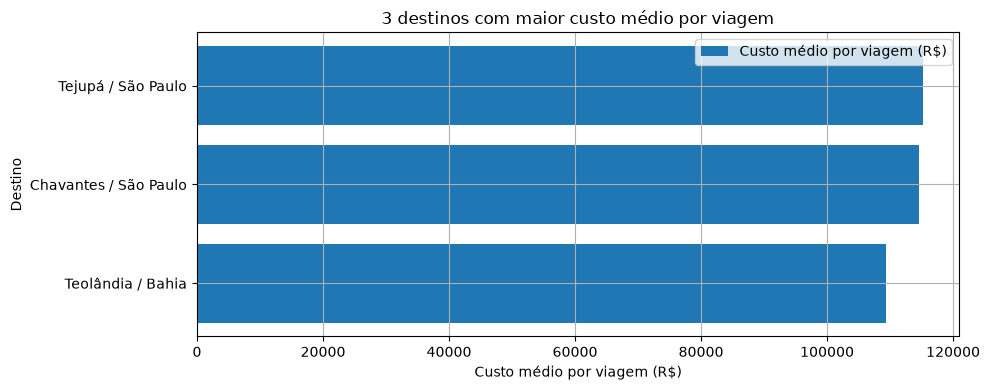

In [4]:
sql_2 = """
WITH destinos_unicos AS (
    SELECT DISTINCT id_viagem, destino_cidade, destino_uf
    FROM silver_trecho
    WHERE destino_cidade IS NOT NULL
      AND destino_uf IS NOT NULL
)
SELECT (d.destino_cidade || ' / ' || d.destino_uf) AS destino,
       COUNT(*) AS quantidade_viagens,
       ROUND(AVG(v.valor_total), 2) AS custo_medio
FROM destinos_unicos d
JOIN silver_viagem v ON v.id_viagem = d.id_viagem
GROUP BY d.destino_cidade, d.destino_uf
ORDER BY custo_medio DESC
LIMIT 3;
"""
df2 = consultar(sql_2)
mostrar_tabela(df2)
grafico_barras(df2, 'destino', 'custo_medio',
              '3 destinos com maior custo médio por viagem',
              'Custo médio por viagem (R$)', '02_destinos_custo_medio.png')

### Pergunta 3 — Qual foi a viagem de maior duração e qual seu custo total?
A duração inclui o dia de início e o de término. Em caso de empate, a primeira linha aparece por custo total decrescente.

,id_viagem,nome_viajante,destinos,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,Mogi Mirim/SP,2025-01-13,2026-01-31,384,0.00


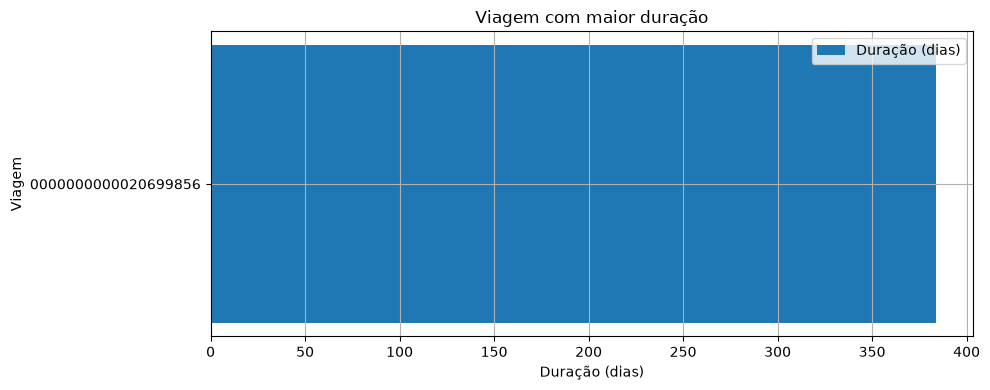

In [5]:
sql_3 = """
SELECT id_viagem, nome_viajante, destinos, data_inicio, data_fim,
       duracao_dias, valor_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC
LIMIT 1;
"""
df3 = consultar(sql_3)
mostrar_tabela(df3)
df3_plot = df3.copy()
df3_plot['viagem'] = df3_plot['id_viagem']
grafico_barras(df3_plot, 'viagem', 'duracao_dias',
              'Viagem com maior duração', 'Duração (dias)',
              '03_viagem_mais_longa.png')

## 4. Construção da camada Gold (TABELA + VIEWS com JOIN e GROUP BY)

O SQL em `sql/3_criar_gold.sql` cria uma tabela materializada convencional (`gold_resumo_orgaos`) e duas views (`gold_visao_pagamentos`, `gold_visao_trechos`). A tabela agrega primeiro os pagamentos por viagem para evitar somas duplicadas.

In [6]:
sql_gold = Path('sql/3_criar_gold.sql').read_text(encoding='utf-8')
try:
    with conexao.cursor() as cursor:
        cursor.execute(sql_gold)
    conexao.commit()
    print('Camada Gold criada com sucesso!')
except Exception:
    conexao.rollback()
    raise

# Demonstracao da tabela Gold fisica.
mostrar_tabela(consultar("""
    SELECT * FROM gold_resumo_orgaos
    ORDER BY total_pago DESC LIMIT 10
"""))

Camada Gold criada com sucesso!


,orgao_superior,quantidade_viagens,custo_total_viagens,total_pago
0,Ministério da Justiça e Segurança Pública,75742,486933121.65,488831110.61
1,Ministério da Defesa,61912,156070304.49,156549767.91
2,Ministério da Educação,65295,111291349.34,111897434.35
3,Ministério do Meio Ambiente e Mudança do Clima,19413,49697710.16,50123043.80
4,Ministério da Previdência Social,8190,40417309.06,40659494.63
5,Ministério da Saúde,8672,39049825.61,39517918.03
6,Ministério da Fazenda,11854,32474392.19,32666017.41
7,Ministério dos Povos Indígenas,5101,26286915.37,26441142.20
8,Ministério das Relações Exteriores,2014,25533548.96,25724337.16
9,Ministério do Desenvolvimento Agrário e Agricu...,8581,21998422.21,22171683.47


## 5. Quatro perguntas respondidas usando a Gold (com três gráficos)

### Pergunta 4 — Qual o tipo de pagamento com maior valor médio?
A média global é uma **média ponderada pelo número de pagamentos**, não a média simples das médias dos órgãos.

,tipo_pagamento,quantidade_pagamentos,valor_medio
0,DIÁRIAS,401463,2078.28
1,PASSAGEM,188985,1878.34
2,Serviço correlato: seguro,4894,447.51
3,RESTITUIÇÃO,11574,245.70


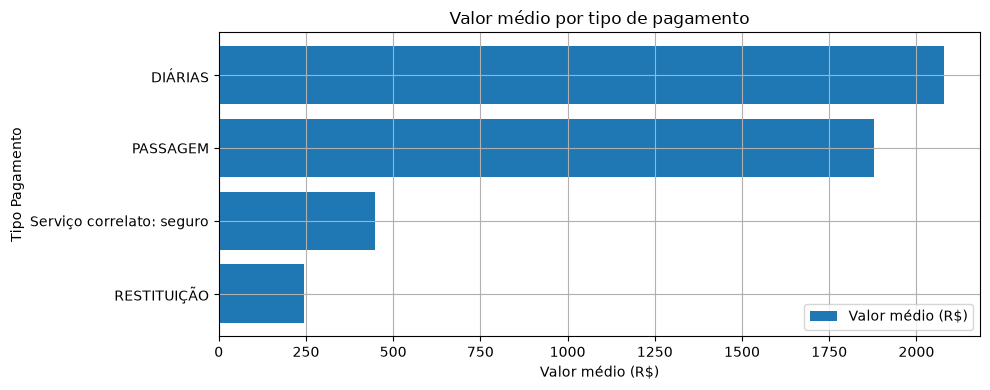

In [7]:
sql_4 = """
SELECT tipo_pagamento,
       SUM(quantidade_pagamentos) AS quantidade_pagamentos,
       ROUND(SUM(valor_total_pago) / NULLIF(SUM(quantidade_pagamentos), 0), 2)
           AS valor_medio
FROM gold_visao_pagamentos
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC;
"""
df4 = consultar(sql_4)
mostrar_tabela(df4)
grafico_barras(df4, 'tipo_pagamento', 'valor_medio',
              'Valor médio por tipo de pagamento', 'Valor médio (R$)',
              '04_pagamento_valor_medio.png')

### Pergunta 5 — Qual o meio de transporte mais utilizado nos trechos?

,meio_transporte,total_trechos
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


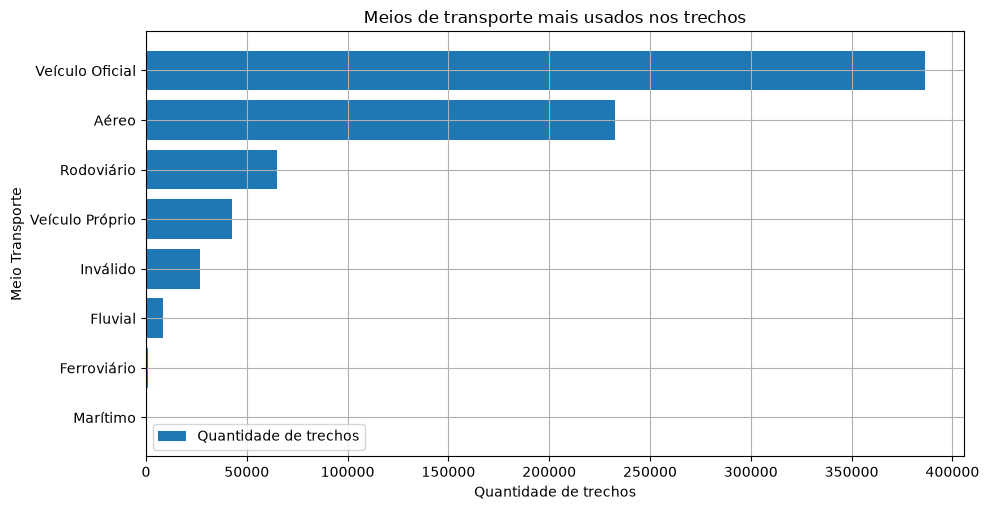

In [8]:
sql_5 = """
SELECT meio_transporte, SUM(quantidade_trechos) AS total_trechos
FROM gold_visao_trechos
GROUP BY meio_transporte
ORDER BY total_trechos DESC;
"""
df5 = consultar(sql_5)
mostrar_tabela(df5)
grafico_barras(df5.head(10), 'meio_transporte', 'total_trechos',
              'Meios de transporte mais usados nos trechos',
              'Quantidade de trechos', '05_transportes.png')

### Pergunta 6 — Qual UF de destino aparece em mais trechos?
Os nomes na fonte de dados podem aparecer por extenso, como "Santa Catarina".

,destino_uf,total_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


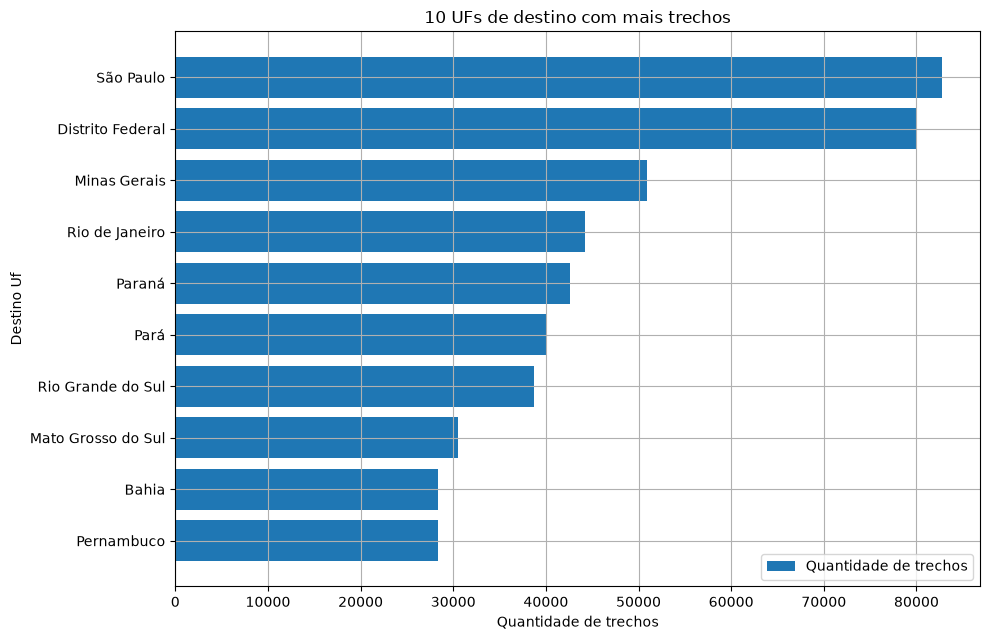

In [9]:
sql_6 = """
SELECT destino_uf, SUM(quantidade_trechos) AS total_trechos
FROM gold_visao_trechos
WHERE destino_uf <> 'Sem informação'
GROUP BY destino_uf
ORDER BY total_trechos DESC;
"""
df6 = consultar(sql_6)
mostrar_tabela(df6.head(15))
grafico_barras(df6.head(10), 'destino_uf', 'total_trechos',
              '10 UFs de destino com mais trechos',
              'Quantidade de trechos', '06_ufs_destino.png')

### Pergunta 7 — Qual órgão pagador desembolsou o maior valor total?
Esta resposta utiliza **o nome do órgão que efetuou o pagamento**, não o órgão superior que autorizou a viagem.

In [10]:
sql_7 = """
SELECT orgao_pagador,
       SUM(valor_total_pago) AS total_pago,
       SUM(quantidade_pagamentos) AS qtd_pagamentos
FROM gold_visao_pagamentos
GROUP BY orgao_pagador
ORDER BY total_pago DESC
LIMIT 10;
"""
df7 = consultar(sql_7)
mostrar_tabela(df7)
print('Órgão pagador com maior desembolso:', df7.iloc[0]['orgao_pagador']
      if not df7.empty else 'sem dados')

,orgao_pagador,total_pago,qtd_pagamentos
0,Fundo Nacional de Segurança Pública,278481047.89,79816
1,Sigiloso,200484801.68,93141
2,Comando da Aeronáutica,81769144.77,46193
3,Instituto Nacional do Seguro Social,37427601.45,18324
4,Comando do Exército,36872643.95,22837
5,Ministério da Gestão e da Inovação em Serviços...,35541760.71,20291
6,Instituto Brasileiro do Meio Ambiente e dos Re...,31589853.15,16758
7,Ministério das Relações Exteriores - Unidades ...,25605376.38,3705
8,Receita Federal do Brasil,23811027.00,18917
9,Ministério da Agricultura e Pecuária - Unidade...,22899880.25,15864


Órgão pagador com maior desembolso: Fundo Nacional de Segurança Pública


## 6. Síntese e considerações

- O Ministério da Justiça e Segurança Pública lidera o custo total, com **R$ 486,9 milhões** em 75.742 viagens. Em seguida aparecem Defesa (**R$ 156,1 milhões**) e Educação (**R$ 111,3 milhões**). O ranking considera o custo total calculado por viagem; não deve ser confundido com o total de pagamentos, que é uma métrica distinta.
- Os destinos com maior custo médio — Tejupá/SP, Chavantes/SP e Teolândia/BA — têm **uma viagem cada**, com valores entre R$ 109 mil e R$ 115 mil. São casos isolados, não evidência de que esses destinos sejam geralmente mais caros; a média deve ser interpretada junto à quantidade de viagens.
- Diárias têm o maior valor médio por pagamento (**R$ 2.078,28**), seguidas de passagens (**R$ 1.878,34**). A comparação é ponderada pela quantidade de pagamentos de cada tipo. Restituições e serviços correlatos também aparecem na base, com médias menores.
- Veículo oficial é o meio de transporte mais registrado (386.424 trechos), seguido por aéreo (232.666). São Paulo é a UF de destino mais frequente (82.722 trechos), próxima ao Distrito Federal (79.962). Essas contagens representam trechos, não viagens únicas nem pessoas.
- **Atenção à qualidade e ao recorte temporal:** embora a amostra seja descrita como referente a seis meses de 2025, a viagem de maior duração começa em 13/01/2025 e termina em 31/01/2026, totalizando 384 dias, com custo registrado de R$ 0,00. A data final ultrapassa o período anunciado e o valor zero merece validação; recomenda-se conferir a origem e as regras de cálculo antes de interpretar esse registro como representativo. Também há 26.659 trechos classificados como “Inválido”, que devem ser investigados antes de conclusões sobre o uso dos meios de transporte.
- A camada Gold consolida os dados para responder às perguntas e evita duplicar viagens ao associá-las a vários pagamentos. Ainda assim, os resultados dependem da qualidade e da cobertura dos registros Silver; os gráficos são descritivos e não explicam as causas dos valores observados.

**Próximos passos:** validar datas, valores zerados e categorias inválidas; explicitar o período efetivamente coberto; e, em análises futuras, apresentar a quantidade de observações junto às médias e oferecer filtros por período, órgão, destino e tipo de pagamento.

**Fonte:** Portal da Transparência, base de Viagens a Serviço, amostra fornecida na atividade avaliativa e descrita como referente a seis meses de 2025. Os valores e as contagens refletem os registros disponíveis após as transformações deste projeto.

In [11]:
conexao.close()
print('Análise concluída e conexão encerrada.')

Análise concluída e conexão encerrada.
